# 04 · Realistic forecasts: how much skill survives real NBM forecasts?

Everything so far fed the model **observed** future weather. Here the same models (trained 2016 to 2023) get **archived NOAA National Blend of Models (NBM)** forecasts instead:
- 24 h window: forecast valid at each hour, issued ~24 h earlier (lead day 1)
- 72 h window: lead day 1 / 2 / 3 for hours 1-24 / 25-48 / 49-72

Test period: **Apr to Dec 2025** (unfrozen soil). The NBM archive starts 2024-10-09, so Oct 2024 to Mar 2025 is used only to estimate forecast error for the augmentation experiment.

In [1]:
# Setup: works locally (pip install -e . from the repo root) and on Google Colab
import sys, warnings
warnings.filterwarnings("ignore")
if "google.colab" in sys.modules:
    # Upload soilcast.zip to Google Drive (MyDrive) first
    from google.colab import drive
    drive.mount("/content/drive")
    !unzip -q -o /content/drive/MyDrive/soilcast.zip -d /content
    %cd /content/soilcast
    !pip install -q -e ".[gpu-trees]"
    sys.path.insert(0, "/content/soilcast/src")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from soilcast.config import PROCESSED, RAW, RESULTS
from soilcast.plotting import set_style, model_color, SERIES, MUTED
set_style()
pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)
RESULTS.mkdir(exist_ok=True)

In [2]:
from soilcast.features import FEATURE_SETS, sm_valid
from soilcast.evaluate import sm_metrics
from soilcast.models import fit_predict_delta, make_model
P = pd.read_parquet(PROCESSED / "features_5cm_perfect.parquet")
N = pd.read_parquet(PROCESSED / "features_5cm_nbm.parquet")
train = P[sm_valid(P) & P.year.between(2016, 2023)]
key = ["station", "time_utc"]
test_p = P[sm_valid(P) & (P.time_utc >= "2025-04-01")]
test_n = N[sm_valid(N) & (N.time_utc >= "2025-04-01")]
test_p = test_p.merge(test_n[key], on=key); test_n = test_n.merge(test_p[key], on=key)   # identical rows
test_p, test_n = test_p.sort_values(key).reset_index(drop=True), test_n.sort_values(key).reset_index(drop=True)
assert (test_p.sm.values == test_n.sm.values).all()
print(len(train), "train rows;", len(test_p), "test rows (same rows in both test sets)")

148397 train rows; 20066 test rows (same rows in both test sets)


In [3]:
rows = []
for fs in ["sensors_24h", "sensors+forecast", "sensors+forecast+soil", "v2_engineered"]:
    cols = FEATURE_SETS[fs]
    for kind in ("linear", "gbm"):
        m = make_model(kind).fit(train[cols], train.sm_t24 - train.sm)
        for src, t in (("perfect", test_p), ("NBM", test_n)):
            r = sm_metrics(t.sm_t24, {"persistence": t.sm, "model": t.sm + m.predict(t[cols])}, t.sm,
                           test_p.fc_precip_24h)  # rain-event subset defined by OBSERVED rain for both
            r = r.iloc[1:].assign(model=f"{kind} | {fs}", forecast=src)
            rows.append(r)
pers = sm_metrics(test_p.sm_t24, {"persistence": test_p.sm}, test_p.sm, test_p.fc_precip_24h).assign(forecast="-")
res = pd.concat([pers] + rows, ignore_index=True)
res.to_csv(RESULTS / "04_perfect_vs_nbm_5cm.csv", index=False)
res[["model", "forecast", "RMSE_pp", "skill_vs_persistence", "RMSE_pp_rain_events", "n"]]

,model,forecast,RMSE_pp,skill_vs_persistence,RMSE_pp_rain_events,n
0,persistence,-,2.395,0.000,6.498,20066
1,linear | sensors_24h,perfect,2.316,0.033,6.357,20066
2,linear | sensors_24h,NBM,2.316,0.033,6.357,20066
3,gbm | sensors_24h,perfect,2.262,0.055,6.159,20066
4,gbm | sensors_24h,NBM,2.262,0.056,6.158,20066
5,linear | sensors+forecast,perfect,1.589,0.337,3.940,20066
6,linear | sensors+forecast,NBM,2.055,0.142,5.350,20066
7,gbm | sensors+forecast,perfect,1.414,0.410,3.461,20066
8,gbm | sensors+forecast,NBM,2.046,0.146,5.229,20066
9,linear | sensors+forecast+soil,perfect,1.580,0.340,3.855,20066


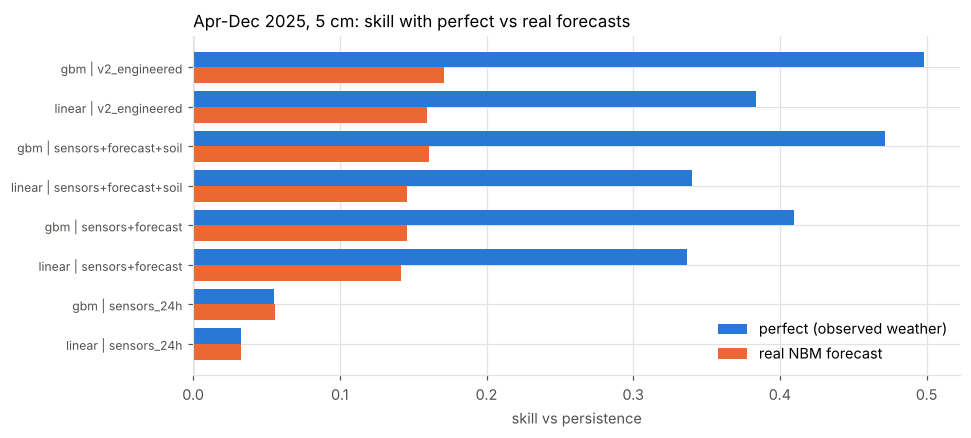

In [4]:
piv = res[res.forecast != "-"].pivot(index="model", columns="forecast", values="skill_vs_persistence")
piv = piv.loc[[f"{k} | {fs}" for fs in ["sensors_24h", "sensors+forecast", "sensors+forecast+soil", "v2_engineered"] for k in ("linear", "gbm")]]
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(piv))
ax.barh(y + .2, piv["perfect"], .4, color=SERIES[0], label="perfect (observed weather)")
ax.barh(y - .2, piv["NBM"], .4, color=SERIES[1], label="real NBM forecast")
ax.set_yticks(y, piv.index, fontsize=8); ax.axvline(0, color=MUTED, lw=.8)
ax.set(xlabel="skill vs persistence", title="Apr-Dec 2025, 5 cm: skill with perfect vs real forecasts"); ax.legend();

## Can training on noisy forecasts help?
We have no archived forecasts for 2016 to 2023, so the model learned to trust rain inputs completely. One fix: **add realistic forecast error to the training inputs** so the model learns to hedge. Error statistics come from NBM vs observed for Oct 2024 to Mar 2025 only (no overlap with the test).

In [5]:
cal = P.merge(N, on=key, suffixes=("_o", "_f"))
cal = cal[(cal.time_utc < "2025-04-01")][["fc_precip_24h_o", "fc_precip_24h_f"]].dropna()
o, f = cal.fc_precip_24h_o, cal.fc_precip_24h_f
wet = o >= 1
p_miss = ((f < 0.5) & wet).sum() / wet.sum()                 # forecast ~dry when it rained
p_false = ((f >= 1) & (o < 0.5)).sum() / (o < 0.5).sum()      # forecast rain when dry
ratio = np.log((f[wet & (f >= 0.5)] + .1) / (o[wet & (f >= 0.5)] + .1))
print(f"calibration windows {len(cal)}; P(miss | rain) {p_miss:.2f}; P(false alarm | dry) {p_false:.3f}; "
      f"log-ratio mean {ratio.mean():.2f} sd {ratio.std():.2f}")
false_amounts = f[(f >= 1) & (o < 0.5)].to_numpy()

def corrupt(df, rng):
    df = df.copy()
    r = df.fc_precip_24h.to_numpy().copy()
    wet = r >= 1
    miss = wet & (rng.random(len(r)) < p_miss)
    noisy = r * np.exp(rng.normal(ratio.mean(), ratio.std(), len(r)))
    r_new = np.where(wet, np.where(miss, 0.0, noisy), r)
    fa = (r < 0.5) & (rng.random(len(r)) < p_false)
    r_new[fa] = rng.choice(false_amounts, fa.sum())
    scale = np.where(r > 0, r_new / np.maximum(r, 1e-6), 0)
    df["fc_precip_6h"] = np.where(fa, r_new / 4, df.fc_precip_6h * scale)
    df["fc_precip_24h"] = r_new
    rr = np.clip(r_new, None, 50)
    for c, base in (("fc_rain_x_deficit", df.porosity - df.sm), ("fc_rain_x_clay", df.clay),
                    ("fc_rain_x_awc", df.awc), ("fc_rain_x_sand", df.sand)):
        df[c] = rr * base
    df["fc_rain_log"] = np.log1p(rr)
    return df

rng = np.random.default_rng(7)
cols = FEATURE_SETS["v2_engineered"]
aug = pd.concat([train, corrupt(train, rng)], ignore_index=True)    # clean + corrupted copy
m_aug = make_model("gbm").fit(aug[cols], aug.sm_t24 - aug.sm)
m_clean = make_model("gbm").fit(train[cols], train.sm_t24 - train.sm)
out = sm_metrics(test_n.sm_t24, {"persistence": test_n.sm,
                                 "gbm v2, trained clean": test_n.sm + m_clean.predict(test_n[cols]),
                                 "gbm v2, trained with forecast noise": test_n.sm + m_aug.predict(test_n[cols])},
                 test_n.sm, test_p.fc_precip_24h)
out.to_csv(RESULTS / "04_noise_augmentation_5cm.csv", index=False)
out

calibration windows 13767; P(miss | rain) 0.18; P(false alarm | dry) 0.043; log-ratio mean -0.02 sd 0.76


,model,RMSE_pp,MAE_pp,skill_vs_persistence,RMSE_pp_rain_events,n,n_rain_events
0,persistence,2.395,1.146,0.000,6.498,20066,2053
1,"gbm v2, trained clean",1.985,0.875,0.171,4.980,20066,2053
2,"gbm v2, trained with forecast noise",1.966,0.906,0.179,4.849,20066,2053


## Takeaways
- The realistic numbers (NBM rows) are the ones to report. The perfect-forecast numbers are the ceiling a better rain forecast could reach.
- Rain forecast skill is the bottleneck: NBM 24 h rain correlates ~0.6 with observed (notebook 01).
- If noise augmentation helps, train with it by default. Even better: archive the NWS forecasts for Jolly Lane from now on (`scripts/archive_nws_forecast.py`) so future models train on real forecasts.